In [2]:
# Data libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge, ElasticNet, LinearRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.linear_model import Lasso
from matplotlib.patches import Patch
import matplotlib.dates as mdates
import seaborn as sns


# Used in helper functions
labels = ["avg", "min", "max"]

# Cleaning choice
tidal_threshold = 1.5  # median daily range (m) above this = tide gauge

# Time split
cutoff_final, end_final = "2026-08-31", "2026-11-30"  # final test 
cv_years = [2022, 2023, 2024, 2025]                   # one fold per autumn
cutoff = pd.Timestamp(cutoff_final)                   # used by clean_error

# Features, target 
target = "z"
season_cols = ["sin_doy", "cos_doy"]

# model arguments
seed = 0
cv_results = []


In [3]:
def reshape_long(avg_df, min_df, max_df, loc_df, start = "2017-04-01", drop_tidal = True):
    """
    Convert the df from Wide -> long, drop tidal series, attach coordinates
    Input:
    - avg_df, min_df, max_df: Average, Minimum and Maximum df
    - loc_df: locations df
    - start: observations before this date will be removed
    - drop_tidal: boolean value, should tidal-level stations be removed
    Returns:
    - river long df: df with one row per station per day and columns
    """
    data = [avg_df, min_df, max_df]
    column = ["County", "Station_Name", "Observation_ID", "date"]
    long_df = {}

    for df, lab in zip(data, labels):
        if drop_tidal:
            df = df[~df["Observation_ID"].str.contains("tidal-level", na = False)]

        long_df[lab] = df.melt(id_vars = column[0:3], var_name = "date", value_name = lab)
        long_df[lab]["date"] = pd.to_datetime(long_df[lab]["date"], format = "%d/%m/%Y")
        long_df[lab] = long_df[lab][long_df[lab]["date"] >= start]

    river_long = (long_df["avg"]
                 .merge(long_df["min"], on = column, how = "left")
                 .merge(long_df["max"], on = column, how = "left"))

    n_before = len(river_long)  # row count before attaching locations, if it changes a station is duplicated in loc_df
    river_long = river_long.merge(loc_df, on = column[0:3], how = "left")
    assert len(river_long) == n_before, "location merge duplicated rows"

    # a station name that didnt match gives NaN coordinates
    print(f"Number of missing latitude: {river_long['Latitude'].isna().sum()}")
    print(f"Number of missing longitude: {river_long['Longitude'].isna().sum()}")

    for col in column[0:3]:
        river_long[col] = river_long[col].astype("category")

    return river_long

def clean_error(df, k = 20):
    """
    Cleaning: sentinels (cell-wise), outliers (train only), order check
    Input:
    - df: long data frame that contains Observation_ID, date, avg, min, max
    - k: number of IQRs beyond Q1/Q3 at which a value is an outlier
    Returns:
    - df2 : a copy of the df with the bad values replaced by NaN values
    """
    
    df2 = df.copy()

    large_vals = df2[labels].isin([99999.999, -999999.999, -99]) | (df2[labels].abs() >= 9999)
    # cell by cell, only the bad value becomes NaN not the whole row
    df2[labels] = df2[labels].where(~large_vals, np.nan)

    for lab in labels:
        # quartiles from training dates only (no leakage)
        train_val = df2[lab].where(df2["date"] <= cutoff)
        per_sta = train_val.groupby(df2["Observation_ID"], observed = True)

        q1 = per_sta.transform(lambda s: s.quantile(0.25))
        q3 = per_sta.transform(lambda s: s.quantile(0.75))
        sd = per_sta.transform("std")

        iqr = (q3 - q1).where(q3 - q1 > 0, sd)  # if iqr = 0 we use std
        outlier = ((df2[lab] > q3 + k * iqr) | (df2[lab] < q1 - k * iqr))

        df2.attrs[f"sentinel_{lab}"] = int(large_vals[lab].sum())
        df2.attrs[f"outliers_{lab}"] = int(outlier.sum())

        # count flagged test values, but only remove the training ones
        df2.attrs[f"outliers_{lab}_test"] = int((outlier & (df2["date"] > cutoff)).sum())
        df2.loc[outlier & (df2["date"] <= cutoff), lab] = np.nan

    bad = (df2["min"] > df2["avg"]) | (df2["avg"] > df2["max"])
    df2.attrs["order_violations"] = int(bad.sum())
    df2.loc[bad, labels] = np.nan

    return df2

def drop_ids(df, min_years = 3, cutoff = cutoff_final, threshold = tidal_threshold):
    
    """
    INPUT:
    - df (long+cleaned dataframe): contains Observation_ID, date, avg, min, max
    - min_years: minimum number of years of non missing avg data a station needs to be kept
    - cutoff: last day of training period
    - threshold: max median daily range 
    
    OUTPUT:
    - keep_df: copy of df containing only stations we keep
    """

    cutoff = pd.Timestamp(cutoff) 

    is_train = df["date"] <= cutoff
    train_obs = df["avg"].notna() & is_train
    years = train_obs.groupby(df["Observation_ID"], observed = True).sum() / 365.25
    
    median_range = (df["max"] - df["min"]).where(is_train).groupby(df["Observation_ID"], observed = True).median()

    keep_ids = years[(years >= min_years) & (median_range <= threshold)].index

    keep_df = df[df["Observation_ID"].isin(keep_ids)].copy()
    keep_df.attrs["dropped_short"] = int((years < min_years).sum())
    keep_df.attrs["dropped_tidal"] = int((median_range > threshold).sum())
    keep_df.attrs["kept_ids"]      = int(len(keep_ids))

    return keep_df

def add_features(df, cutoff):
    
    """
    INPUT:
    - df: long df containing Observation_ID, date, avg, min, max
    - cutoff: last training date ("2025-08-31" for validation, "2026-08-31" for final test)

    OUTPUT:
    - df2: copy of df with columns added (station stats use training rows only):
        * sta_mean, sta_std: station's mean and stdev of avg level
        * z: standardized level (target)
        * daily_range: station's median (max - min), divided by its IQR of avg
        * sin_doy, cos_doy: day-of-year waves
    """
    
    df2 = df.copy()  
    cutoff = pd.Timestamp(cutoff)
    is_train = df2["date"] <= cutoff 

    train_val = df2["avg"].where(is_train)                 
    per_sta = train_val.groupby(df2["Observation_ID"], observed=True)

    df2["sta_mean"] = per_sta.transform("mean")
    df2["sta_std"]  = per_sta.transform("std").replace(0, np.nan)   # stdev 0 → NaN (avoid ±∞)
    df2["z"] = (df2["avg"] - df2["sta_mean"]) / df2["sta_std"]

    rng_train = (df2["max"] - df2["min"]).where(is_train)
    q1 = per_sta.transform(lambda s: s.quantile(0.25))
    q3 = per_sta.transform(lambda s: s.quantile(0.75))
    iqr = (q3 - q1).replace(0, np.nan)  # IQR 0 → NaN
    df2["daily_range"] = rng_train.groupby(df2["Observation_ID"], observed=True).transform("median") / iqr

    theta = 2 * np.pi * df2["date"].dt.dayofyear / 365.25
    df2["sin_doy"],  df2["cos_doy"]  = np.sin(theta),     np.cos(theta)      
    
    return df2

def get_coefs(m, plot = False, feature_names = None, figsize = (5,5), figtitle = None, intercept = True):
    """Returns model coefficients in a data frame for a fitted linear model."""
    w = np.concatenate(([m[-1].intercept_] if isinstance(m, sklearn.pipeline.Pipeline) else [m.intercept_],
                            m[-1].coef_ if isinstance(m, sklearn.pipeline.Pipeline) else m.coef_))
    if feature_names is None:
        feature_names = m[:-1].get_feature_names_out() if isinstance(m, sklearn.pipeline.Pipeline) else m.feature_names_in_
    feature_names = np.concatenate((['intercept'], feature_names))
    w_df = pd.DataFrame({'feature': feature_names, 'coef': w}).sort_values("coef", ascending=False)

    if plot:
        if not intercept:
            w_df = w_df[w_df['feature'] != 'intercept']
        plt.figure(figsize=figsize)
        plt.barh(w_df['feature'], w_df['coef'])
        plt.ylabel('Features')
        plt.xlabel('Coefficient Value')
        plt.axvline(x=0, color=".5")
        if figtitle is not None:
            plt.title(figtitle)
        plt.grid()
        plt.show()

    return w_df


In [4]:

def make_fold_lag(df, year):
    """
    Build one rolling-origin fold for reading B (one-day-ahead).
    Input:
    - df: cleaned long df (river_long2, no station filter yet)
    - year: fold year; fit = up to 31 Aug of year, validate = 1 Sep – 30 Nov of year
    Returns:
    - fit, val: rows with target z and all lag / clim features observed
    """
    c = pd.Timestamp(f"{year}-08-31")       # last training day
    v_end = pd.Timestamp(f"{year}-11-30")   # last validation day

    # station filter, mu_s, sigma_s from this fold's training period only (no leakage)
    df_k = drop_ids(df, min_years = 3, cutoff = c)
    feat = add_features(df_k, cutoff = c)
    feat["month"] = feat["date"].dt.month

    # lags: per station, backward shifts only (each row sees only earlier days)
    feat = feat.sort_values(["Observation_ID", "date"])
    g = feat.groupby("Observation_ID", observed = True)["z"]
    feat["lag1"] = g.shift(1)                      # yesterday
    feat["lag2"] = g.shift(2)                      # day before yesterday
    feat["trend"] = feat["lag1"] - feat["lag2"]    # > 0: river rising

    # lag7: mean of the previous 7 days (today excluded), kept only if >= 4 observed
    past = pd.concat([g.shift(j) for j in range(1, 8)], axis = 1)
    feat["lag7"] = past.mean(axis = 1)
    feat["lag7"] = feat["lag7"].where(past.notna().sum(axis = 1) >= 4)

    # climatology: station x month mean of z, from training rows only
    fit = feat[feat["date"] <= c]
    clim = fit.groupby(["Observation_ID", "month"], observed = True)["z"].mean().rename("clim")
    feat = feat.merge(clim, on = ["Observation_ID", "month"], how = "left")

    # split by date, drop rows with a missing target or feature
    fit = feat[feat["date"] <= c]
    val = feat[(feat["date"] > c) & (feat["date"] <= v_end)]
    cols = ["z", "clim", "lag1", "lag2", "lag7"]
    return fit.dropna(subset = cols), val.dropna(subset = cols)


def cv_score(model, df, years, features, target = "z", n_sub = None, fold_fn = make_fold_lag):
    """
    Cross-validation score (any model, any fold builder, optional subsample)
    Returns the RMSE on each validation autumn.
    - n_sub: train on a random subsample of this size (kernel models)
    - fold_fn: make_fold_lag
    """
    scores = np.zeros(len(years))
    for i, y in enumerate(years):
        fit, val = fold_fn(df, y)
        if n_sub is not None:
            fit = fit.sample(n = n_sub, random_state = 0)
        model.fit(fit[features], fit[target])
        pred = model.predict(val[features])
        scores[i] = root_mean_squared_error(val[target], pred)
    return scores

class RBFFeatures(BaseEstimator, TransformerMixin):
    """ Sparse kernel machine: training inputs as centroids (lecture notes)
    phi(x) = (k(x, x_1), ..., k(x, x_N)) with the training inputs as centroids."""
    def __init__(self, gamma = 1.0):
        self.gamma = gamma

    def fit(self, X, y = None):
        self.centres_ = np.asarray(X)
        return self

    def transform(self, X):
        return rbf_kernel(np.asarray(X), self.centres_, gamma = self.gamma)


def score(name, pred_z, y_true, df):

    """
    INPUT:
    - name: model name (for the results table)
    - pred_z: predicted z
    - y_true: true z
    - df: matching rows (needs sta_mean, sta_std, avg), e.g. final_df.loc[X_test.index]

    OUTPUT:
    - dict with RMSE (z), RMSE (m), MAE (m)
    """

    pred_m = pred_z * df["sta_std"] + df["sta_mean"]    # back to metres

    return {"model":    name,
            "RMSE (z)": root_mean_squared_error(y_true, pred_z),
            "RMSE (m)": root_mean_squared_error(df["avg"], pred_m),
            "MAE (m)":  mean_absolute_error(df["avg"], pred_m)}

def add_cv(name, scores, param = None):
    cv_results.append({"model": name, 
                       "param": param,
                       "cv_mean": scores.mean(), 
                       "cv_sd": scores.std(ddof = 1)})

In [5]:
river_avg = pd.read_csv("avg_river_levels.csv")
river_min = pd.read_csv("min_river_levels.csv")
river_max = pd.read_csv("max_river_levels.csv")
river_location = pd.read_csv("monitoring_locations.csv")

river_long = reshape_long(river_avg, river_min, river_max, river_location)
river_long2 = clean_error(river_long)
river_long3 = drop_ids(river_long2)

feats = ["lag1", "trend", "lag7", "sin_doy", "cos_doy", "clim"]

folds_B = {}
for y in cv_years:
    folds_B[y] = make_fold_lag(river_long2, y)

def fold_B(df, y):
    return folds_B[y]

river_long2.attrs, river_long3.attrs

Number of missing latitude: 0
Number of missing longitude: 0


({'sentinel_avg': 76,
  'outliers_avg': 112,
  'outliers_avg_test': 1,
  'sentinel_min': 32,
  'outliers_min': 179,
  'outliers_min_test': 5,
  'sentinel_max': 47,
  'outliers_max': 145,
  'outliers_max_test': 0,
  'order_violations': 0},
 {'sentinel_avg': 76,
  'outliers_avg': 112,
  'outliers_avg_test': 1,
  'sentinel_min': 32,
  'outliers_min': 179,
  'outliers_min_test': 5,
  'sentinel_max': 47,
  'outliers_max': 145,
  'outliers_max_test': 0,
  'order_violations': 0,
  'dropped_short': 8,
  'dropped_tidal': 11,
  'kept_ids': 361})

## Some EDA

Stations: 361
Counties: 35
Missing avg station-days: 12.01 %
Dates: 2017-04-01 to 2026-08-31


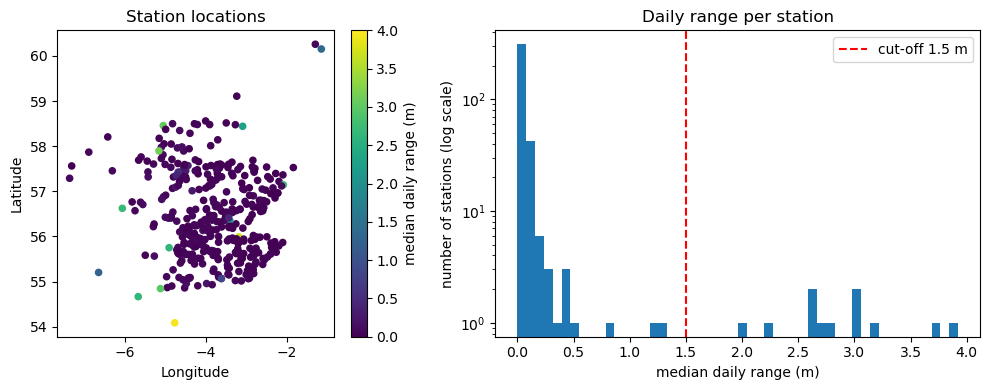

In [6]:
# Inspect train_df (training period only, kept stations)
train_df = river_long3[river_long3["date"] <= cutoff].copy()

print("Stations:", train_df["Observation_ID"].nunique())   # number of obs_id
print("Counties:", train_df["County"].nunique())           # number of counties
print(f"Missing avg station-days: {train_df['avg'].isna().mean() * 100:.2f} %")
print("Dates:", train_df["date"].min().date(),             # first day
      "to", train_df["date"].max().date())                 # last day

# Station map, histogram BEFORE filtering (river_long2 = cleaned, tide gauges still in)
train_clean = river_long2[river_long2["date"] <= cutoff]

# one row per station: location (training data only)
sta_loc = train_clean.groupby("Observation_ID", observed = True).agg(lat = ("Latitude", "first"),
                                                                     lon = ("Longitude", "first"))

# median daily range per station (training data only)
median_range = (train_clean["max"] - train_clean["min"]).groupby(train_clean["Observation_ID"], observed = True).median()

fig, axes = plt.subplots(1, 2, figsize = (10, 4), gridspec_kw = {"width_ratios": [1, 1.4]})   # map narrower, histogram wider

# (left) station map coloured by median daily range
sta_map = axes[0].scatter(sta_loc["lon"], sta_loc["lat"], c = median_range.loc[sta_loc.index],
                          cmap = "viridis", s = 20, vmin = 0, vmax = 4)
fig.colorbar(sta_map, ax = axes[0], label = "median daily range (m)")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude"); axes[0].set_title("Station locations")

# (right) histogram of median daily range
median_range.plot.hist(bins = 50, log = True, ax = axes[1])
axes[1].axvline(tidal_threshold, color = "red", linestyle = "--", label = f"cut-off {tidal_threshold} m")
axes[1].set_xlabel("median daily range (m)"); axes[1].set_ylabel("number of stations (log scale)")
axes[1].set_title("Daily range per station")
axes[1].legend()

plt.tight_layout(); plt.show()



In [7]:
train_df[["avg", "min", "max", "Latitude", "Longitude"]].corr()["avg"].round(3)

avg          1.000
min          0.996
max          0.995
Latitude     0.068
Longitude   -0.107
Name: avg, dtype: float64

In [8]:
# order train_df
train_df = train_df.sort_values(["Observation_ID", "date"]).copy()

# avg: grouped by station
per_sta = train_df.groupby("Observation_ID", observed = True)["avg"]

# z-score per station: (today's level − that station's mean) / that station's std
train_df["z"] = (train_df["avg"] - per_sta.transform("mean")) / per_sta.transform("std")

train_df["year"]  = train_df["date"].dt.year        # 2017, 2018, ...
train_df["month"] = train_df["date"].dt.month       # 1–12
train_df["doy"]   = train_df["date"].dt.dayofyear   # day of year, 1–366

# sample of non-missing rows (seed fixed -> same sample every run)
sample = train_df.dropna(subset = ["z"]).sample(5000, random_state = seed)

sample["season"] = sample["month"].map({6: "Summer", 7: "Summer", 8: "Summer",    # Jun–Aug = end of training
                                        9: "Autumn", 10: "Autumn", 11: "Autumn"}) # Sep–Nov = forecast period

# autumn rows of the sample
autumn = sample[sample["season"] == "Autumn"]

# all autumn rows, and mean autumn z per station
autumn_train = train_df[train_df["month"].isin([9, 10, 11])]
sta_autumn = autumn_train.groupby("Observation_ID", observed = True).agg(lat = ("Latitude", "first"),
                                                                         lon = ("Longitude", "first"),
                                                                         autumn_z = ("z", "mean"))

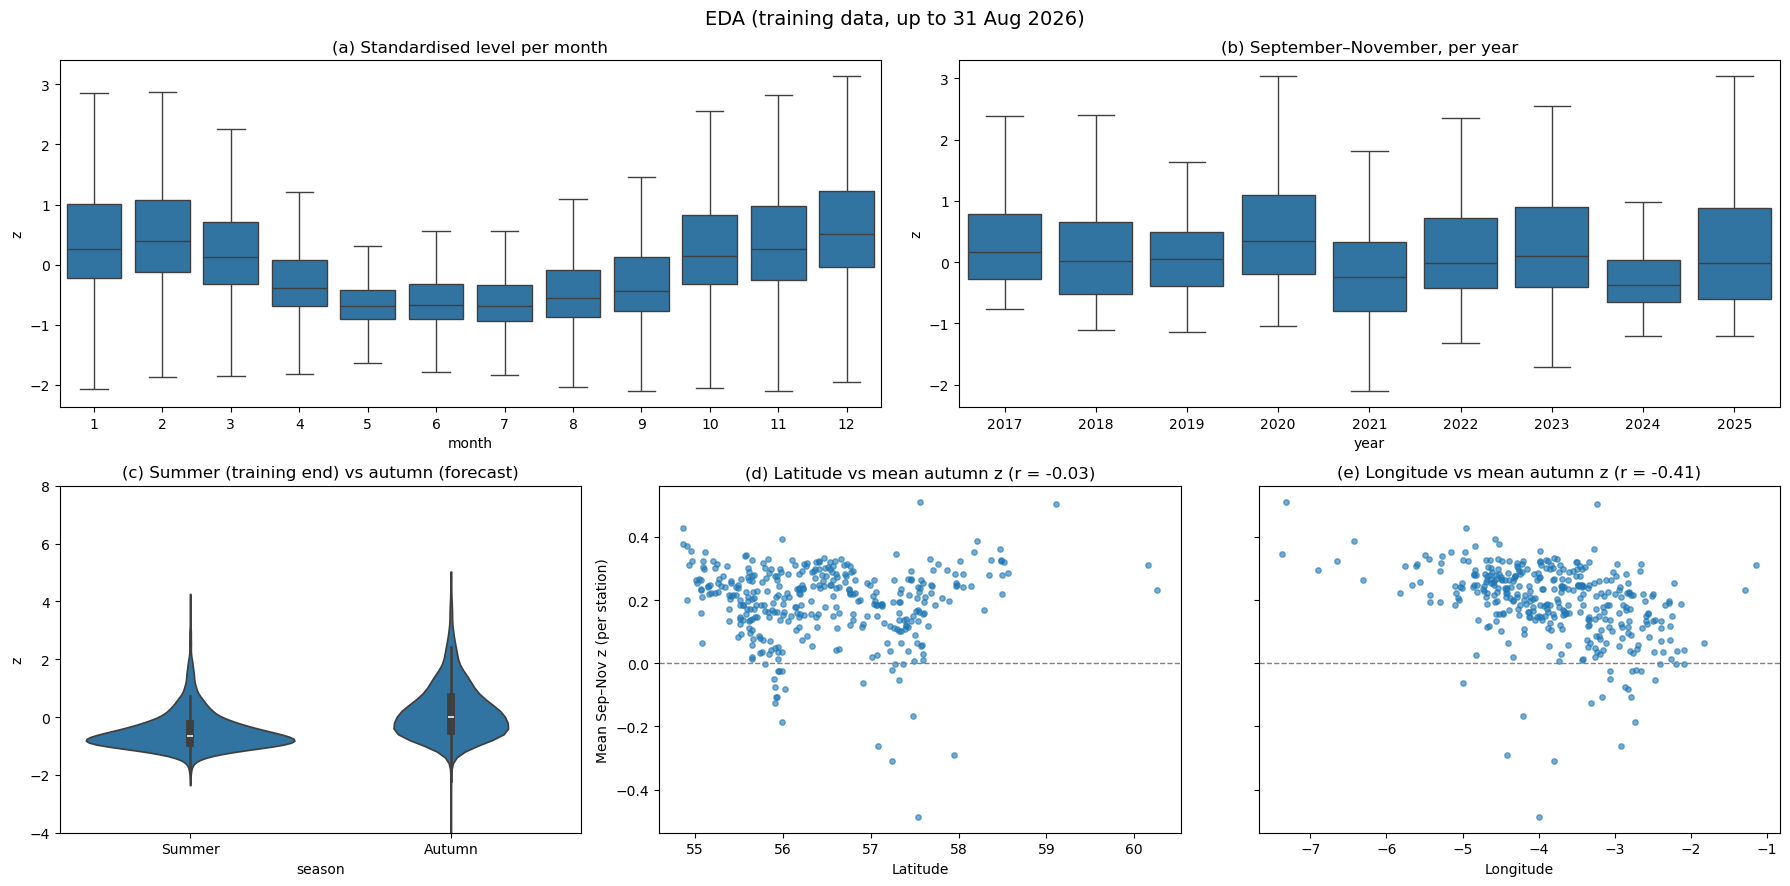

In [9]:
# EDA figure: 2 plots on top, 3 below
fig = plt.figure(figsize = (18, 9))
gs  = fig.add_gridspec(2, 6)  # 2 rows × 6 columns

ax_month  = fig.add_subplot(gs[0, 0:3])                   # top-left
ax_year   = fig.add_subplot(gs[0, 3:6])                   # top-right
ax_season = fig.add_subplot(gs[1, 0:2])                   # bottom-left
ax_lat    = fig.add_subplot(gs[1, 2:4])                   # bottom-middle
ax_lon    = fig.add_subplot(gs[1, 4:6], sharey = ax_lat)  # bottom-right

# (a) z per month
sns.boxplot(data = train_df, x = "month", y = "z", showfliers = False, ax = ax_month)
ax_month.set_title("(a) Standardised level per month")

# (b) autumn per year
sns.boxplot(data = autumn, x = "year", y = "z", showfliers = False, ax = ax_year)
ax_year.set_title("(b) September–November, per year")

# (c) summer vs autumn
sns.violinplot(data = sample.dropna(subset = ["season"]), x = "season", y = "z",
               cut = 0, order = ["Summer", "Autumn"], ax = ax_season)
ax_season.set_ylim(-4, 8)
ax_season.set_title("(c) Summer (training end) vs autumn (forecast)")

# (d, e) location vs mean autumn z, one dot per station
for ax, col, name, tag in [(ax_lat, "lat", "Latitude", "(d)"),
                           (ax_lon, "lon", "Longitude", "(e)")]:
    r = sta_autumn[col].corr(sta_autumn["autumn_z"])
    ax.scatter(sta_autumn[col], sta_autumn["autumn_z"], s = 15, alpha = 0.6)
    ax.axhline(0, color = "grey", linestyle = "--", lw = 1)
    ax.set_xlabel(name); ax.set_title(f"{tag} {name} vs mean autumn z (r = {r:.2f})")

ax_lat.set_ylabel("Mean Sep–Nov z (per station)")
ax_lon.tick_params(labelleft = False)

fig.suptitle("EDA (training data, up to 31 Aug 2026)", fontsize = 14)
plt.tight_layout(); plt.show()

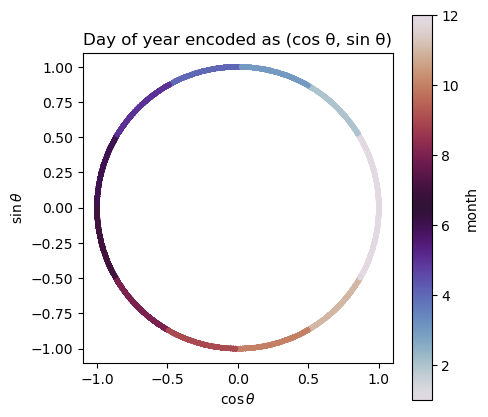

In [10]:
# season encoding: day of year on a circle (31 Dec next to 1 Jan)
theta = 2 * np.pi * sample["doy"] / 365.25

fig, ax = plt.subplots(figsize = (5, 5))
sc = ax.scatter(np.cos(theta), np.sin(theta), c = sample["month"], cmap = "twilight", s = 8)
fig.colorbar(sc, ax = ax, label = "month")
ax.set_xlabel(r"$\cos\theta$"); ax.set_ylabel(r"$\sin\theta$")
ax.set_title("Day of year encoded as (cos θ, sin θ)")
ax.set_aspect("equal"); plt.show()

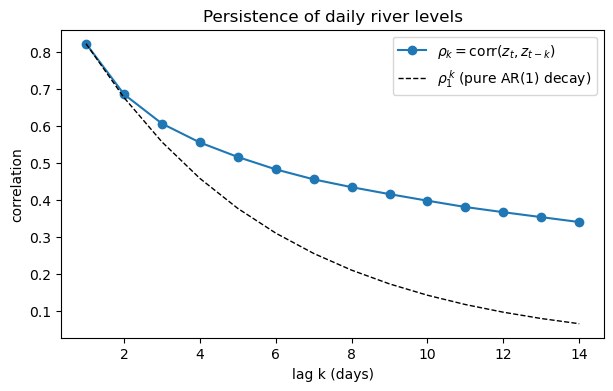

In [11]:
# autocorrelation of z: how similar is today to k days ago? (per station, training data)
g = train_df.groupby("Observation_ID", observed = True)["z"]
lags = range(1, 15)
acf = [train_df["z"].corr(g.shift(k)) for k in lags]   # rows are daily, so shift(k) = k days back

fig, ax = plt.subplots(figsize = (7, 4))
ax.plot(lags, acf, marker = "o", label = r"$\rho_k = \mathrm{corr}(z_t, z_{t-k})$")
ax.plot(lags, [acf[0] ** k for k in lags], "k--", lw = 1, label = r"$\rho_1^{\,k}$ (pure AR(1) decay)")
ax.set_xlabel("lag k (days)"); ax.set_ylabel("correlation")
ax.set_title("Persistence of daily river levels")
ax.legend(); plt.show()

## Here, we start the model exploration, evaluation and tuning

In [ ]:
# Here, we construct our baseline model for the regression
base = cv_score(LinearRegression(), river_long2, cv_years, ["sin_doy", "cos_doy"], fold_fn = fold_B)
base_cv_score = base.mean()
add_cv("Baseline model", base, param = None)
base_cv_score

1.0809761874330188

In [ ]:
# The first model, linear regression 
linear_regression = LinearRegression()
lr_score = cv_score(linear_regression, river_long2, cv_years, feats, fold_fn = fold_B)
lr_score_score = lr_score.mean()
add_cv("Linear Regression", lr_score, param = None)
lr_score_score

0.6738542373489279

In [ ]:
# Now, we try Ridge, Lasso and Elastic Net Regressions
alphas = np.logspace(-4, 3, 8)
for a in alphas:
    for name, reg in [("Ridge", Ridge(alpha = a)),
                      ("Lasso", Lasso(alpha = a)),
                      ("Elastic net", ElasticNet(alpha = a, l1_ratio = 0.5))]:
        
        model  = make_pipeline(StandardScaler(), reg)
        scores = cv_score(model, river_long2, cv_years, features = feats, fold_fn = fold_B)    
        add_cv(name, scores, param = a)
res = pd.DataFrame(cv_results)
res

,model,param,cv_mean,cv_sd
0,Baseline model,NaN,1.080976,0.177900
1,Linear Regression,NaN,0.673854,0.149393
2,Ridge,0.0001,0.673854,0.149393
3,Lasso,0.0001,0.673862,0.149412
4,Elastic net,0.0001,0.673857,0.149403
5,Ridge,0.0010,0.673854,0.149393
6,Lasso,0.0010,0.673936,0.149589
7,Elastic net,0.0010,0.673878,0.149493
8,Ridge,0.0100,0.673854,0.149393
9,Lasso,0.0100,0.674995,0.151366


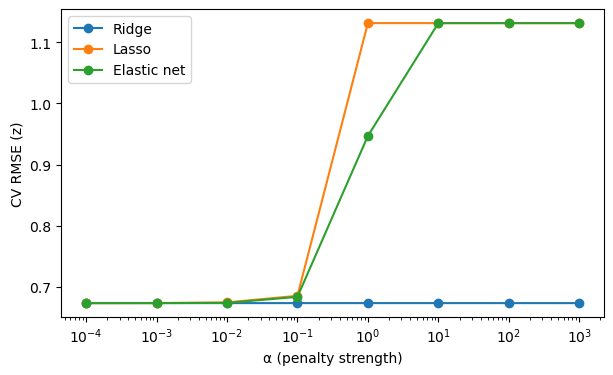

In [9]:
fig, ax = plt.subplots(figsize = (7, 4))

for name in ["Ridge", "Lasso", "Elastic net"]:
    r = res[res["model"] == name]
    ax.plot(r["param"], r["cv_mean"], marker = "o", label = name)
    
ax.set_xscale("log"); ax.set_xlabel("α (penalty strength)"); ax.set_ylabel("CV RMSE (z)")
ax.legend(); plt.show()

In [ ]:
# Now, we try polynomial regression with different polynomial degrees
poly_scores = {}
degrees = [1, 2, 3]

for d in degrees:
    model = make_pipeline(StandardScaler(),
                          PolynomialFeatures(degree = d, include_bias = False), 
                          LinearRegression())
    poly_scores[d] = cv_score(model, river_long2, cv_years, features = feats, fold_fn = fold_B)
    add_cv("Polynomial", poly_scores[d], param = d)

res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])
res[res["model"].str.startswith("Polynomial")]

,model,param,cv_mean,cv_sd
26,Polynomial,1.0,0.673854,0.149393
27,Polynomial,2.0,0.678307,0.157325
28,Polynomial,3.0,0.693773,0.161531


In [ ]:
poly_scores_ridge = {}
for d in degrees:
    for a in [1, 100, 1e4]:
        model = make_pipeline(StandardScaler(),
                                  PolynomialFeatures(degree = d, include_bias = False), 
                                  Ridge(alpha = a))
        poly_scores_ridge[a, d] = cv_score(model, river_long2, cv_years, features = feats, fold_fn = fold_B)
        add_cv("Polynomial+Ridge", poly_scores_ridge[a, d], param = (a, d))

res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])
res[res["model"].str.startswith("Polynomial+Ridge")]

,model,param,cv_mean,cv_sd
29,Polynomial+Ridge,"(1, 1)",0.673854,0.149393
30,Polynomial+Ridge,"(100, 1)",0.673850,0.149393
31,Polynomial+Ridge,"(10000.0, 1)",0.673765,0.149484
32,Polynomial+Ridge,"(1, 2)",0.678307,0.157325
33,Polynomial+Ridge,"(100, 2)",0.678301,0.157326
34,Polynomial+Ridge,"(10000.0, 2)",0.678014,0.157428
35,Polynomial+Ridge,"(1, 3)",0.693773,0.161531
36,Polynomial+Ridge,"(100, 3)",0.693756,0.161523
37,Polynomial+Ridge,"(10000.0, 3)",0.692280,0.161307


In [ ]:
krr_scores = {}
for g in [0.003, 0.01, 0.03, 0.1, 0.3]:
    for a in [0.01, 0.1, 1]:
        krr_B = make_pipeline(StandardScaler(),
                      KernelRidge(kernel = "rbf", alpha = a, gamma = g))
        krr_scores[a, g] = cv_score(krr_B, river_long2, cv_years, feats, n_sub = 3000, fold_fn = fold_B)
        add_cv("KernelRidge", krr_scores[a, g], param=(a, g))


res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])
res[res["model"].str.startswith("KernelRidge")]

,model,param,cv_mean,cv_sd
38,KernelRidge,"(0.1, 0.01)",0.678727,0.173000
39,KernelRidge,"(1, 0.01)",0.691973,0.182199
40,KernelRidge,"(0.1, 0.03)",0.688461,0.180400
41,KernelRidge,"(1, 0.03)",0.699285,0.193486
42,KernelRidge,"(0.1, 0.1)",0.728979,0.206593
43,KernelRidge,"(1, 0.1)",0.726308,0.216952
44,KernelRidge,"(0.1, 0.3)",0.787896,0.239189
45,KernelRidge,"(1, 0.3)",0.770417,0.251617


In [ ]:
sk_scores = {}
for g in [0.01, 0.03, 0.1]:
    for a in [1e-5, 1e-4, 1e-3]:
        sk_pipe_B = make_pipeline(StandardScaler(),
                                  RBFFeatures(gamma = g),
                                  Lasso(alpha = a, max_iter = 5000, selection="random", tol=1e-3))

        sk_scores[a, g] = cv_score(sk_pipe_B, river_long2, cv_years, feats, n_sub = 2000, fold_fn = fold_B)
        add_cv("SparseKernelMachine", sk_scores[a, g], param=(a, g))
        print(a, g, "centroids kept:", (sk_pipe_B[-1].coef_ != 0).sum())
        
res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])
res[res["model"].str.startswith("SparseKernelMachine")]

0.0001 0.01 centroids kept: 27
0.001 0.01 centroids kept: 8
0.0001 0.03 centroids kept: 38
0.001 0.03 centroids kept: 20


c:\Users\sosom\anaconda3\envs\myenv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.283e+01, tolerance: 2.220e+00
  model = cd_fast.enet_coordinate_descent(


0.0001 0.1 centroids kept: 77
0.001 0.1 centroids kept: 31


,model,param,cv_mean,cv_sd
46,SparseKernelMachine,"(0.0001, 0.01)",0.697878,0.180232
47,SparseKernelMachine,"(0.001, 0.01)",0.695126,0.177204
48,SparseKernelMachine,"(0.0001, 0.03)",0.693936,0.181208
49,SparseKernelMachine,"(0.001, 0.03)",0.706662,0.190172
50,SparseKernelMachine,"(0.0001, 0.1)",0.720735,0.199300
51,SparseKernelMachine,"(0.001, 0.1)",0.718271,0.203390


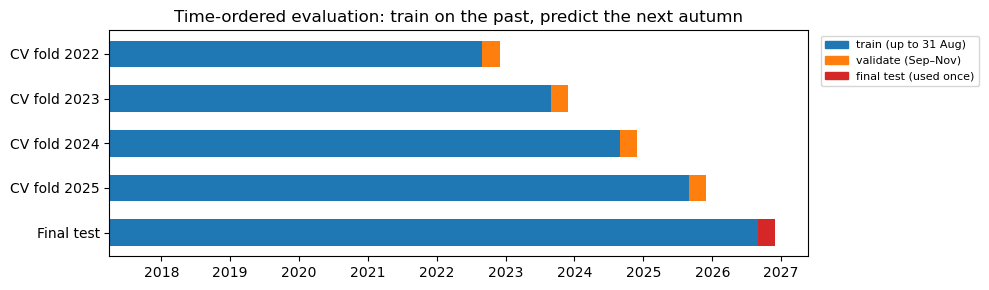

In [ ]:

start = pd.Timestamp("2017-04-01")
rows = [(f"CV fold {y}", f"{y}-08-31", f"{y}-11-30") for y in cv_years] + [("Final test", cutoff_final, end_final)]

fig, ax = plt.subplots(figsize = (10, 3))

for i, (name, cut, end) in enumerate(rows):
    cut, end = pd.Timestamp(cut), pd.Timestamp(end)
    ax.barh(i, cut - start, left = start, color = "tab:blue", height = 0.6)  # training part
    ax.barh(i, end - cut, left = cut, height = 0.6,                          # predicted autumn
            color = "tab:red" if name == "Final test" else "tab:orange")

ax.set_yticks(range(len(rows)), [r[0] for r in rows]); ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(handles = [Patch(color = "tab:blue",   label = "train (up to 31 Aug)"),
                     Patch(color = "tab:orange", label = "validate (Sep–Nov)"),
                     Patch(color = "tab:red",    label = "final test (used once)")],
          loc = "upper left", bbox_to_anchor = (1.01, 1), fontsize = 8)

ax.set_title("Time-ordered evaluation: train on the past, predict the next autumn")
plt.tight_layout(); plt.show()

In [28]:

# results table 
res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])

# best setting of each model 
best = res.loc[res.groupby("model")["cv_mean"].idxmin()].copy()
best = best.sort_values("cv_mean").reset_index(drop = True)
best[["model", "param", "cv_mean", "cv_sd"]].round(3)

,model,param,cv_mean,cv_sd
0,Polynomial+Ridge,"(10000.0, 1)",0.674,0.149
1,Ridge,1000.0,0.674,0.149
2,Linear Regression,None,0.674,0.149
3,Polynomial,1,0.674,0.149
4,Elastic net,0.0001,0.674,0.149
5,Lasso,0.0001,0.674,0.149
6,KernelRidge,"(0.1, 0.01)",0.679,0.173
7,SparseKernelMachine,"(0.0001, 0.03)",0.694,0.181
8,Persistence (today = yesterday),None,0.720,0.164
9,Baseline model,None,1.081,0.178


In [29]:
folds_table = pd.DataFrame({"Seasonal LR": base,
                            "Linear AR": lr_score,
                            "Kernel ridge": krr_scores[0.1, 0.01],
                            "Sparse kernel": sk_scores[1e-4, 0.03]},
                           index = cv_years).round(3)
folds_table["AR − seasonal"] = (folds_table["Linear AR"] - folds_table["Seasonal LR"]).round(3)
folds_table["KRR − AR"] = (folds_table["Kernel ridge"] - folds_table["Linear AR"]).round(3)
folds_table

,Seasonal LR,Linear AR,Kernel ridge,Sparse kernel,AR − seasonal,KRR − AR
2022,1.095,0.711,0.721,0.759,-0.384,0.010
2023,1.318,0.846,0.883,0.896,-0.472,0.037
2024,0.897,0.485,0.467,0.466,-0.412,-0.018
2025,1.014,0.653,0.644,0.654,-0.361,-0.009


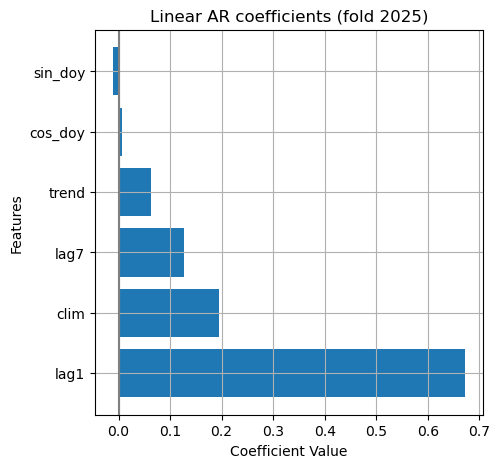

,feature,coef
1,lag1,0.672036
6,clim,0.194368
3,lag7,0.126776
2,trend,0.062691
5,cos_doy,0.006122
4,sin_doy,-0.011169


In [ ]:
train_25, val_25 = folds_B[2025]
ar_25 = LinearRegression().fit(train_25[feats], train_25["z"])
get_coefs(ar_25, plot = True, figtitle = "Linear AR coefficients (fold 2025)", intercept = False)

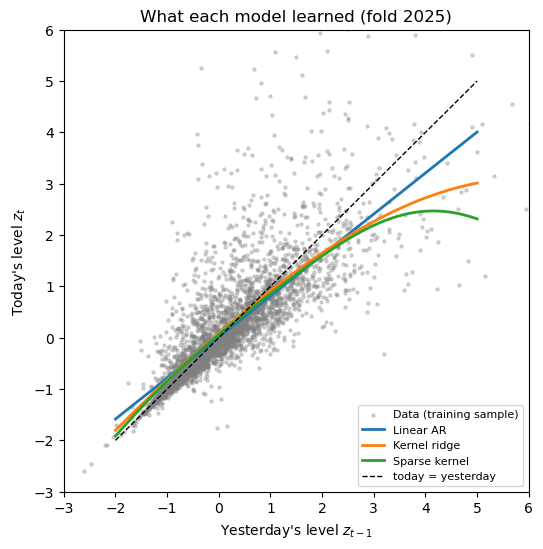

In [34]:
train_25, val_25 = folds_B[2025]
sub3000 = train_25.sample(3000, random_state = seed)
sub2000 = train_25.sample(2000, random_state = seed)

# best setting of each model, fitted on the same fold
models_B = {
    "Linear AR": LinearRegression().fit(train_25[feats], train_25["z"]),
    "Kernel ridge": make_pipeline(StandardScaler(),
                                  KernelRidge(kernel = "rbf", alpha = 0.1, gamma = 0.01)
                                  ).fit(sub3000[feats], sub3000["z"]),
    "Sparse kernel": make_pipeline(StandardScaler(),
                                   RBFFeatures(gamma = 0.03),
                                   Lasso(alpha = 1e-4, max_iter = 5000, selection = "random", tol = 1e-3)
                                   ).fit(sub2000[feats], sub2000["z"]),
}

# data cloud (training sample)
s = train_25.sample(5000, random_state = seed)
fig, ax = plt.subplots(figsize = (6, 6))
ax.scatter(s["lag1"], s["z"], s = 5, alpha = 0.3, color = "grey", label = "Data (training sample)")

# vary yesterday's level, hold the rest at typical values (steady river, mid-October)
grid = pd.DataFrame({"lag1": np.linspace(-2, 5, 100)})
grid["lag7"], grid["trend"], grid["clim"] = grid["lag1"], 0, 0
theta = 2 * np.pi * 288 / 365.25
grid["sin_doy"], grid["cos_doy"] = np.sin(theta), np.cos(theta)

for name, m in models_B.items():
    ax.plot(grid["lag1"], m.predict(grid[feats]), lw = 2, label = name)
ax.plot([-2, 5], [-2, 5], "k--", lw = 1, label = "today = yesterday")

ax.set_xlabel("Yesterday's level $z_{t-1}$"); ax.set_ylabel("Today's level $z_t$")
ax.set_title("What each model learned (fold 2025)")
ax.legend(fontsize = 8)
ax.set_xlim(-3, 6); ax.set_ylim(-3, 6); plt.show()

In [35]:
train_rows = {"Linear AR": train_25, "Kernel ridge": sub3000, "Sparse kernel": sub2000}

gap = pd.DataFrame([{"model": name,
                     "RMSE train": root_mean_squared_error(train_rows[name]["z"], m.predict(train_rows[name][feats])),
                     "RMSE val":   root_mean_squared_error(val_25["z"], m.predict(val_25[feats]))}
                    for name, m in models_B.items()]).set_index("model")
gap["gap"] = gap["RMSE val"] - gap["RMSE train"]
gap.round(3)

,RMSE train,RMSE val,gap
model,,,
Linear AR,0.558,0.653,0.095
Kernel ridge,0.564,0.644,0.080
Sparse kernel,0.551,0.654,0.103


In [36]:
train26, test26 = make_fold_lag(river_long2, 2026)
final_ar = LinearRegression().fit(train26[feats], train26["z"])
seasonal = LinearRegression().fit(train26[season_cols], train26["z"])

test_results = pd.DataFrame([
    score("Seasonal LR", seasonal.predict(test26[season_cols]), test26["z"], test26),
    score("Linear AR (final)", final_ar.predict(test26[feats]), test26["z"], test26),
]).set_index("model").round(3)
test_results

,RMSE (z),RMSE (m),MAE (m)
model,,,
Seasonal LR,0.955,0.190,0.135
Linear AR (final),0.717,0.122,0.071


In [37]:
test_rows = test26.copy()
test_rows["pred_z"]  = final_ar.predict(test26[feats])
test_rows["pred_m"]  = test_rows["pred_z"] * test_rows["sta_std"] + test_rows["sta_mean"]   # back to metres
test_rows["seas_m"]  = seasonal.predict(test26[season_cols]) * test_rows["sta_std"] + test_rows["sta_mean"]
test_rows["err_z"]   = (test_rows["z"] - test_rows["pred_z"]).abs()      # for ranking (fair across river sizes)
test_rows["abs_err"] = (test_rows["avg"] - test_rows["pred_m"]).abs()    # in metres, for the reader

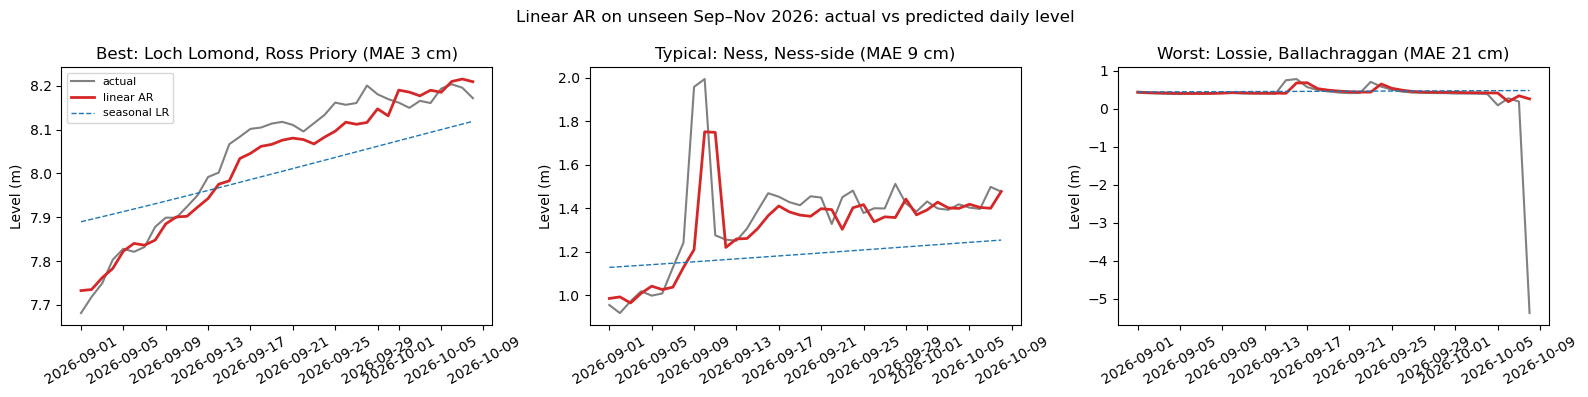

In [ ]:
sta_err = test_rows.groupby("Observation_ID", observed = True)["err_z"].mean().sort_values()
picks = {"Best": sta_err.index[0], "Typical": sta_err.index[len(sta_err) // 2], "Worst": sta_err.index[-1]}

fig, axes = plt.subplots(1, 3, figsize = (16, 4))
for ax, (label, sta_id) in zip(axes, picks.items()):
    sta = test_rows[test_rows["Observation_ID"] == sta_id].sort_values("date")
    mae_cm = sta["abs_err"].mean() * 100
    ax.plot(sta["date"], sta["avg"],    color = "grey",     lw = 1.5, label = "actual")
    ax.plot(sta["date"], sta["pred_m"], color = "tab:red",  lw = 2,   label = "linear AR")
    ax.plot(sta["date"], sta["seas_m"], color = "tab:blue", lw = 1, ls = "--", label = "seasonal LR")
    ax.set_title(f"{label}: {sta['Station_Name'].iloc[0]} (MAE {mae_cm:.0f} cm)")
    ax.set_ylabel("Level (m)")
    ax.tick_params(axis = "x", rotation = 30)
axes[0].legend(fontsize = 8)
fig.suptitle("Linear AR on unseen Sep–Oct 2026: actual vs predicted daily level")
plt.tight_layout(); plt.show()

In [39]:
month = test_rows["date"].dt.month
mae_month = pd.DataFrame({
    "Linear AR MAE (cm)":   test_rows["abs_err"].groupby(month).mean() * 100,
    "Seasonal LR MAE (cm)": (test_rows["avg"] - test_rows["seas_m"]).abs().groupby(month).mean() * 100,
}).round(1)
mae_month.index = mae_month.index.map({9: "Sep", 10: "Oct", 11: "Nov"})
mae_month

,Linear AR MAE (cm),Seasonal LR MAE (cm)
date,,
Sep,7.0,13.7
Oct,7.3,12.7


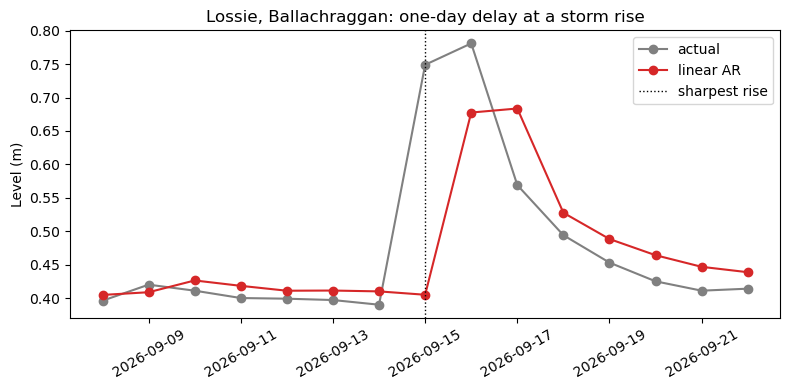

In [40]:
# worst station, around its sharpest one-day rise
sta = test_rows[test_rows["Observation_ID"] == picks["Worst"]].sort_values("date")
peak_date = sta.loc[sta["avg"].diff().idxmax(), "date"]       # day with the biggest jump

win = sta[(sta["date"] >= peak_date - pd.Timedelta(days = 7)) &
          (sta["date"] <= peak_date + pd.Timedelta(days = 7))]

plt.figure(figsize = (8, 4))
plt.plot(win["date"], win["avg"],    marker = "o", color = "grey",    label = "actual")
plt.plot(win["date"], win["pred_m"], marker = "o", color = "tab:red", label = "linear AR")
plt.axvline(peak_date, color = "k", ls = ":", lw = 1, label = "sharpest rise")
plt.ylabel("Level (m)"); plt.xticks(rotation = 30)
plt.title(f"{sta['Station_Name'].iloc[0]}: one-day delay at a storm rise")
plt.legend(); plt.tight_layout(); plt.show()

In [41]:
test26["date"].min(), test26["date"].max(), test26["date"].nunique()

(Timestamp('2026-09-01 00:00:00'), Timestamp('2026-10-08 00:00:00'), 38)